# Voice Cloning Project — Models 1 & 2
### Model 1: Denoising Autoencoder (audio preprocessing)
### Model 2: Variational Autoencoder / VAE (speaker voice-identity embedding)

Dataset: **VCTK Corpus** (multi-speaker English speech)

This notebook:
1. Downloads a subset of VCTK speakers
2. Converts audio to mel-spectrograms
3. Trains a Denoising Autoencoder to clean/reconstruct spectrograms
4. Trains a VAE to learn a per-speaker "voice identity" latent embedding
5. Saves both trained models to Google Drive so later stages (Transformer, Diffusion, GAN) can use them

## 0. Setup — install packages

In [12]:
!pip install torch torchaudio librosa soundfile numpy matplotlib tqdm -q

In [13]:
import os
import glob
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import librosa
import librosa.display
import matplotlib.pyplot as plt
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 1. Mount Google Drive
We'll save checkpoints here so they survive Colab session resets.

In [14]:
from google.colab import drive
drive.mount('/content/drive')

CHECKPOINT_DIR = "/content/drive/MyDrive/voice_cloning_project/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print("Checkpoints will be saved to:", CHECKPOINT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints will be saved to: /content/drive/MyDrive/voice_cloning_project/checkpoints


## 2. Download VCTK (multi-speaker corpus)

**Note:** torchaudio's built-in `VCTK_092(download=True)` currently fails with `HTTPError: 403 Forbidden` —
the University of Edinburgh's datashare server blocks scripted/non-browser downloads. This is a known,
widely-reported issue and is not something wrong with your code.

We use the **Hugging Face mirror** of VCTK instead — no manual downloading, no file uploads, no API keys.
The `datasets` library streams it straight into Colab's cloud storage automatically.

In [15]:
!pip install datasets soundfile -q

In [16]:
from datasets import load_dataset

vctk_dataset = load_dataset(
    "CSTR-Edinburgh/vctk",
    split="train",
    revision="refs/convert/parquet",
)
print("Total utterances in full corpus:", len(vctk_dataset))
print(vctk_dataset[0])
print("Available columns:", vctk_dataset.column_names)

Resolving data files:   0%|          | 0/27 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Loading dataset shards:   0%|          | 0/24 [00:00<?, ?it/s]

Total utterances in full corpus: 88156
{'speaker_id': 'p225', 'audio': <datasets.features._torchcodec.AudioDecoder object at 0x7f72076e0c80>, 'file': '/home/albert/.cache/huggingface/datasets/downloads/extracted/19f4a4613b204b1a28277df81043a81b64b0ef28a8c23514a6fc1eb0d9cc4a75/wav48_silence_trimmed/p225/p225_001_mic1.flac', 'text': 'Please call Stella.', 'text_id': '001', 'age': '23', 'gender': 'F', 'accent': 'English', 'region': 'Southern England', 'comment': ''}
Available columns: ['speaker_id', 'audio', 'file', 'text', 'text_id', 'age', 'gender', 'accent', 'region', 'comment']


## 3. Scope down to a manageable subset of speakers

Training on all 110 speakers is unnecessary and slow on a free Colab GPU.
Pick ~10–15 speakers (mix of accents/genders) — this is plenty to learn a meaningful voice-identity space.

In [17]:
# Pick your subset of speaker IDs here (VCTK speaker codes look like p225, p226, ...)
SELECTED_SPEAKERS = ["p225", "p226", "p227", "p228", "p229",
                      "p230", "p231", "p232", "p233", "p234"]

# Filter the HF dataset down to just these speakers
vctk_subset = vctk_dataset.filter(lambda ex: ex["speaker_id"] in SELECTED_SPEAKERS)
print(f"Filtered to {len(vctk_subset)} utterances across {len(SELECTED_SPEAKERS)} speakers")
assert len(vctk_subset) > 0, "No matching utterances found - print a few speaker_id values from vctk_dataset to check the exact ID format."

# Each row now has: ex['audio']['array'] (waveform, already decoded), ex['audio']['sampling_rate'], ex['speaker_id'], ex['text']

Filter:   0%|          | 0/88156 [00:00<?, ? examples/s]

Filtered to 7428 utterances across 10 speakers


## 4. Audio → Mel-Spectrogram utilities

Both models operate on mel-spectrograms rather than raw waveforms — this is the standard approach in TTS pipelines
and keeps the input size manageable.

In [18]:
SAMPLE_RATE = 22050
N_MELS = 80
N_FFT = 1024
HOP_LENGTH = 256
SEGMENT_FRAMES = 128   # fixed-length spectrogram chunk fed to the models

def waveform_to_mel(y, orig_sr, sr=SAMPLE_RATE, n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP_LENGTH):
    # y: 1-D numpy waveform array (already decoded by the HF datasets library)
    if orig_sr != sr:
        y = librosa.resample(y, orig_sr=orig_sr, target_sr=sr)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft,
                                          hop_length=hop_length, n_mels=n_mels)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    # normalize to roughly [0, 1]
    mel_norm = (mel_db + 80) / 80
    mel_norm = np.clip(mel_norm, 0, 1)
    return mel_norm.astype(np.float32)   # shape: (n_mels, time)

def random_crop_or_pad(mel, target_frames=SEGMENT_FRAMES):
    T = mel.shape[1]
    if T >= target_frames:
        start = random.randint(0, T - target_frames)
        return mel[:, start:start + target_frames]
    else:
        pad_width = target_frames - T
        return np.pad(mel, ((0, 0), (0, pad_width)), mode="constant")

## 5. PyTorch Dataset classes

In [19]:
class DenoisingSpectrogramDataset(Dataset):
    """Returns (noisy_mel, clean_mel) pairs for training the Autoencoder."""
    def __init__(self, hf_subset, noise_std=0.15):
        self.data = hf_subset
        self.noise_std = noise_std

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        ex = self.data[idx]
        y = np.array(ex["audio"]["array"], dtype=np.float32)
        orig_sr = ex["audio"]["sampling_rate"]
        mel = waveform_to_mel(y, orig_sr)
        mel = random_crop_or_pad(mel)
        clean = torch.tensor(mel)
        noisy = clean + torch.randn_like(clean) * self.noise_std
        noisy = torch.clamp(noisy, 0, 1)
        return noisy.unsqueeze(0), clean.unsqueeze(0)   # add channel dim


SPEAKER_TO_IDX = {spk: i for i, spk in enumerate(SELECTED_SPEAKERS)}

class SpeakerSpectrogramDataset(Dataset):
    """Returns (mel, speaker_idx) pairs for training the VAE."""
    def __init__(self, hf_subset):
        self.data = hf_subset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        ex = self.data[idx]
        y = np.array(ex["audio"]["array"], dtype=np.float32)
        orig_sr = ex["audio"]["sampling_rate"]
        mel = waveform_to_mel(y, orig_sr)
        mel = random_crop_or_pad(mel)
        spk_idx = SPEAKER_TO_IDX[ex["speaker_id"]]
        return torch.tensor(mel).unsqueeze(0), spk_idx


# Train/val split (also keep 1-2 speakers fully held out for later zero-shot cloning tests)
HOLDOUT_SPEAKERS = SELECTED_SPEAKERS[-2:]          # last 2 speakers = unseen test speakers
TRAIN_SPEAKERS = SELECTED_SPEAKERS[:-2]

train_hf = vctk_subset.filter(lambda ex: ex["speaker_id"] in TRAIN_SPEAKERS)
holdout_hf = vctk_subset.filter(lambda ex: ex["speaker_id"] in HOLDOUT_SPEAKERS)

print(f"Train utterances: {len(train_hf)} | Held-out (unseen) utterances: {len(holdout_hf)}")

Filter:   0%|          | 0/7428 [00:00<?, ? examples/s]

Filter:   0%|          | 0/7428 [00:00<?, ? examples/s]

Train utterances: 5970 | Held-out (unseen) utterances: 1458


---
## MODEL 1: Denoising Autoencoder

**Job:** clean up noisy/corrupted spectrograms before they're used downstream.
Encoder compresses the noisy mel-spectrogram, decoder reconstructs the clean version.

In [20]:
class DenoisingAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder: 1 x 80 x 128  ->  compressed latent feature map
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),   # -> 16 x 40 x 64
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),  # -> 32 x 20 x 32
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),  # -> 64 x 10 x 16
            nn.ReLU(),
        )
        # Decoder: mirror of encoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),   # output back in [0, 1] range matching normalized mel
        )

    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z)
        return out

In [21]:
# --- Training setup ---
BATCH_SIZE = 16
EPOCHS_AE = 15
LR_AE = 1e-3

train_ds_ae = DenoisingSpectrogramDataset(train_hf)
train_loader_ae = DataLoader(train_ds_ae, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

autoencoder = DenoisingAutoencoder().to(device)
optimizer_ae = torch.optim.Adam(autoencoder.parameters(), lr=LR_AE)
criterion_ae = nn.MSELoss()

ae_losses = []
for epoch in range(EPOCHS_AE):
    autoencoder.train()
    epoch_loss = 0.0
    for noisy, clean in tqdm(train_loader_ae, desc=f"AE Epoch {epoch+1}/{EPOCHS_AE}"):
        noisy, clean = noisy.to(device), clean.to(device)
        optimizer_ae.zero_grad()
        recon = autoencoder(noisy)
        loss = criterion_ae(recon, clean)
        loss.backward()
        optimizer_ae.step()
        epoch_loss += loss.item()
    avg_loss = epoch_loss / len(train_loader_ae)
    ae_losses.append(avg_loss)
    print(f"Epoch {epoch+1}: reconstruction MSE = {avg_loss:.4f}")

# Save checkpoint
torch.save(autoencoder.state_dict(), os.path.join(CHECKPOINT_DIR, "autoencoder.pt"))
print("Saved autoencoder checkpoint.")

AE Epoch 1/15: 100%|██████████| 374/374 [02:56<00:00,  2.12it/s]


Epoch 1: reconstruction MSE = 0.0143


AE Epoch 2/15: 100%|██████████| 374/374 [02:20<00:00,  2.66it/s]


Epoch 2: reconstruction MSE = 0.0041


AE Epoch 3/15: 100%|██████████| 374/374 [02:20<00:00,  2.67it/s]


Epoch 3: reconstruction MSE = 0.0036


... (20 outputs left out)

AE Epoch 14/15: 100%|██████████| 374/374 [02:28<00:00,  2.53it/s]


Epoch 14: reconstruction MSE = 0.0025


AE Epoch 15/15: 100%|██████████| 374/374 [02:27<00:00,  2.54it/s]

Epoch 15: reconstruction MSE = 0.0025
Saved autoencoder checkpoint.


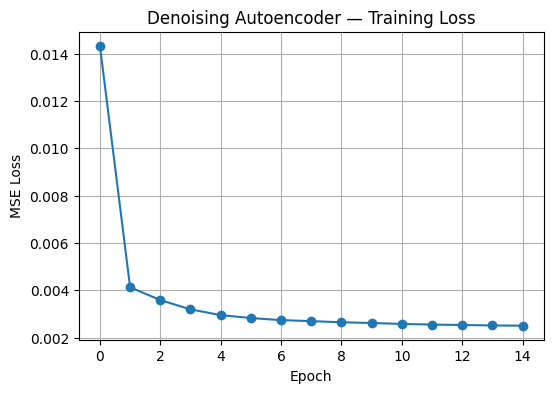

In [22]:
# --- Plot training loss ---
plt.figure(figsize=(6,4))
plt.plot(ae_losses, marker='o')
plt.title("Denoising Autoencoder — Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.grid(True)
plt.show()

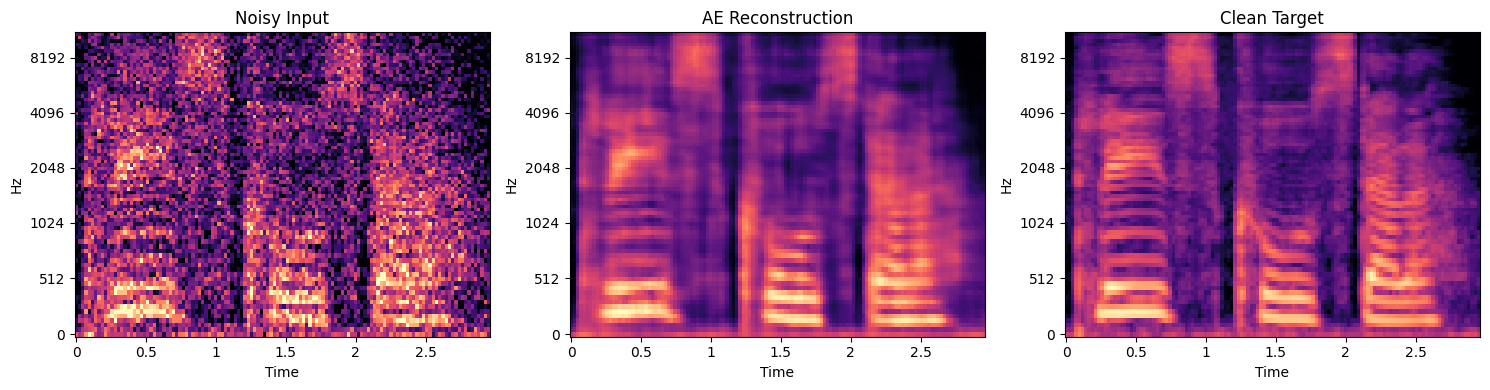

In [23]:
# --- Visualize: noisy input vs reconstructed vs clean target ---
autoencoder.eval()
noisy_sample, clean_sample = train_ds_ae[0]
with torch.no_grad():
    recon_sample = autoencoder(noisy_sample.unsqueeze(0).to(device)).cpu().squeeze()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(
    axes,
    [noisy_sample.squeeze(), recon_sample, clean_sample.squeeze()],
    ["Noisy Input", "AE Reconstruction", "Clean Target"]
):
    librosa.display.specshow(data.numpy(), ax=ax, x_axis='time', y_axis='mel', sr=SAMPLE_RATE)
    ax.set_title(title)
plt.tight_layout()
plt.show()

---
## MODEL 2: VAE — Speaker Voice-Identity Embedding

**Job:** learn a compact latent vector per utterance that captures *who* is speaking
(pitch, timbre, accent) so later stages can condition generation on a target speaker.

Trained with the standard VAE objective: reconstruction loss + KL divergence.
A small auxiliary speaker-classification loss is added on top of the latent `z`
to encourage the embedding space to actually separate speakers (useful for your report's
evaluation — you can show a t-SNE plot of embeddings clustering by speaker).

In [24]:
LATENT_DIM = 64
NUM_SPEAKERS = len(SELECTED_SPEAKERS)

class SpeakerVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_speakers=NUM_SPEAKERS):
        super().__init__()
        # Encoder
        self.enc_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),   # 16 x 40 x 64
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),  # 32 x 20 x 32
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),  # 64 x 10 x 16
            nn.ReLU(),
        )
        self.flatten_dim = 64 * 10 * 16
        self.fc_mu = nn.Linear(self.flatten_dim, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_dim, latent_dim)

        # Decoder
        self.fc_dec = nn.Linear(latent_dim, self.flatten_dim)
        self.dec_conv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),
        )

        # Auxiliary speaker classifier head (helps z separate by speaker identity)
        self.speaker_classifier = nn.Linear(latent_dim, num_speakers)

    def encode(self, x):
        h = self.enc_conv(x)
        h = h.view(h.size(0), -1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.fc_dec(z)
        h = h.view(-1, 64, 10, 16)
        return self.dec_conv(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        speaker_logits = self.speaker_classifier(z)
        return recon, mu, logvar, speaker_logits

In [25]:
def vae_loss(recon, target, mu, logvar, speaker_logits, speaker_labels,
             kl_weight=0.001, speaker_weight=0.5):
    recon_loss = F.mse_loss(recon, target, reduction='mean')
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    speaker_loss = F.cross_entropy(speaker_logits, speaker_labels)
    total = recon_loss + kl_weight * kl_loss + speaker_weight * speaker_loss
    return total, recon_loss, kl_loss, speaker_loss

In [26]:
# --- Training setup ---
EPOCHS_VAE = 25
LR_VAE = 1e-3

train_ds_vae = SpeakerSpectrogramDataset(train_hf)
train_loader_vae = DataLoader(train_ds_vae, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

speaker_vae = SpeakerVAE().to(device)
optimizer_vae = torch.optim.Adam(speaker_vae.parameters(), lr=LR_VAE)

vae_losses = []
for epoch in range(EPOCHS_VAE):
    speaker_vae.train()
    epoch_loss, epoch_recon, epoch_kl, epoch_spk = 0.0, 0.0, 0.0, 0.0
    for mel, spk_idx in tqdm(train_loader_vae, desc=f"VAE Epoch {epoch+1}/{EPOCHS_VAE}"):
        mel, spk_idx = mel.to(device), spk_idx.to(device)
        optimizer_vae.zero_grad()
        recon, mu, logvar, speaker_logits = speaker_vae(mel)
        loss, r_loss, k_loss, s_loss = vae_loss(recon, mel, mu, logvar, speaker_logits, spk_idx)
        loss.backward()
        optimizer_vae.step()
        epoch_loss += loss.item()
        epoch_recon += r_loss.item()
        epoch_kl += k_loss.item()
        epoch_spk += s_loss.item()

    n = len(train_loader_vae)
    vae_losses.append(epoch_loss / n)
    print(f"Epoch {epoch+1}: total={epoch_loss/n:.4f}  recon={epoch_recon/n:.4f}  "
          f"kl={epoch_kl/n:.4f}  speaker_ce={epoch_spk/n:.4f}")

torch.save(speaker_vae.state_dict(), os.path.join(CHECKPOINT_DIR, "speaker_vae.pt"))
print("Saved speaker VAE checkpoint.")

VAE Epoch 1/25: 100%|██████████| 374/374 [02:21<00:00,  2.65it/s]


Epoch 1: total=0.3935  recon=0.0353  kl=5.1110  speaker_ce=0.7063


VAE Epoch 2/25: 100%|██████████| 374/374 [02:19<00:00,  2.69it/s]


Epoch 2: total=0.0865  recon=0.0260  kl=6.4918  speaker_ce=0.1081


VAE Epoch 3/25: 100%|██████████| 374/374 [02:18<00:00,  2.70it/s]


Epoch 3: total=0.0583  recon=0.0235  kl=6.3300  speaker_ce=0.0571


... (40 outputs left out)

VAE Epoch 24/25: 100%|██████████| 374/374 [02:29<00:00,  2.50it/s]


Epoch 24: total=0.0200  recon=0.0124  kl=3.7815  speaker_ce=0.0077


VAE Epoch 25/25: 100%|██████████| 374/374 [02:25<00:00,  2.57it/s]

Epoch 25: total=0.0214  recon=0.0127  kl=4.0200  speaker_ce=0.0093
Saved speaker VAE checkpoint.


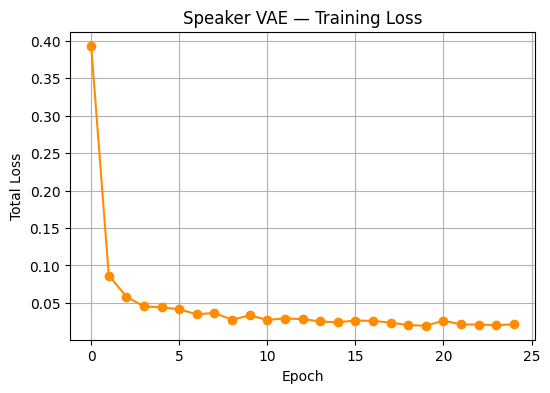

In [27]:
# --- Plot training loss ---
plt.figure(figsize=(6,4))
plt.plot(vae_losses, marker='o', color='darkorange')
plt.title("Speaker VAE — Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.grid(True)
plt.show()

## 6. Evaluate: do the learned embeddings actually separate speakers?

A t-SNE plot of the latent `z` vectors, colored by speaker, is a great figure for your report —
if the VAE learned meaningful voice identities, points from the same speaker should cluster together.

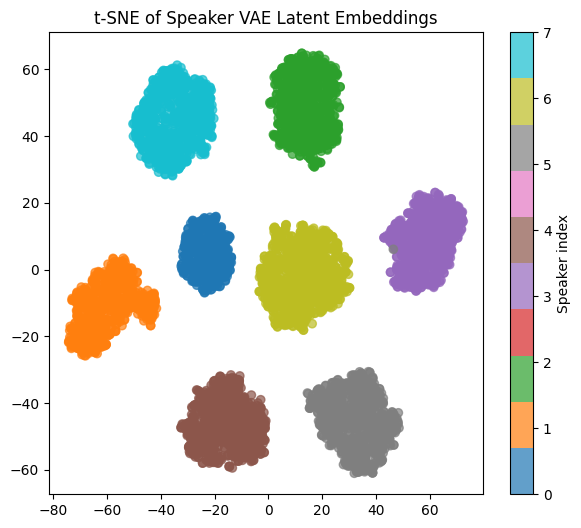

In [28]:
from sklearn.manifold import TSNE

speaker_vae.eval()
all_z, all_labels = [], []

eval_loader = DataLoader(train_ds_vae, batch_size=32, shuffle=False)
with torch.no_grad():
    for mel, spk_idx in eval_loader:
        mel = mel.to(device)
        mu, logvar = speaker_vae.encode(mel)
        all_z.append(mu.cpu().numpy())
        all_labels.append(spk_idx.numpy())

all_z = np.concatenate(all_z, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
z_2d = tsne.fit_transform(all_z)

plt.figure(figsize=(7, 6))
scatter = plt.scatter(z_2d[:, 0], z_2d[:, 1], c=all_labels, cmap='tab10', alpha=0.7)
plt.title("t-SNE of Speaker VAE Latent Embeddings")
plt.colorbar(scatter, ticks=range(len(SELECTED_SPEAKERS)), label="Speaker index")
plt.show()

---
## Summary — what you now have

- `autoencoder.pt` — trained Denoising Autoencoder (cleans spectrograms)
- `speaker_vae.pt` — trained Speaker VAE (produces a 64-dim voice-identity embedding per utterance)
- Both saved to your Google Drive under `voice_cloning_project/checkpoints/`
- Held-out speakers (`HOLDOUT_SPEAKERS`) reserved for testing zero-shot voice cloning later

**Next models to build (Stages 3–5):**
1. **Transformer** — text → acoustic feature sequence
2. **Diffusion model** — refine acoustic features for natural prosody
3. **GAN vocoder** — acoustic features → final playable waveform, conditioned on the VAE speaker embedding

Come back with this notebook's checkpoints and I'll help you build those next.